# Section 3: Preprocessing and evaluation

**Contribution: Muhammadh Azwardeen**

We use the group’s selected CNN without retraining it. This notebook prepares MNIST, measures test performance, examines mistakes and checks the results against the training reference files. Run the cells in order.

Open this notebook from a clone of the repository. Install `requirements.txt` first if the environment needs the dependencies. In Colab, clone `https://github.com/Vertiz2405/mnist-cnn-explainable-ai` and use the cloned project directory. The functions used here are in `src/section3_evaluation.py`.


## 1. Import the tools and locate the project


In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display

cwd = Path.cwd()
candidates = [cwd, cwd.parent, cwd / "mnist-cnn-explainable-ai"]
ROOT = next((p for p in candidates if (p / "src/section3_evaluation.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the repository root or notebooks/ directory. In Colab, clone the repository first.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.section3_evaluation import (
    load_selected_model, split_training_data, preprocess_raw_images,
    evaluate_predictions, check_reference, make_confusion_figure,
    make_error_figure, save_results, checkpoint_sha256,
)

MODEL_PATH = ROOT / "results/models/cnn_selected_for_xai.keras"
REFERENCE_DIR = ROOT / "results/metrics"
OUTPUT_DIR = ROOT / "results/section3"
print("Project:", ROOT.name)
print("TensorFlow:", tf.__version__)


Project: mnist-cnn-explainable-ai
TensorFlow: 2.20.0


The imports provide tools for numbers, tables, plots and the CNN. `Path` locates files. The project root is found from the current directory, so this works from the repository root or its notebooks folder.


## 2. Restore the selected trained model


In [2]:
evaluation_model = load_selected_model(MODEL_PATH)
print("Trained weights loaded successfully.")
print("Input:", evaluation_model.input_shape)
print("Output:", evaluation_model.output_shape)
print("Parameters:", evaluation_model.count_params())


Trained weights loaded successfully.
Input: (None, 28, 28, 1)
Output: (None, 10)
Parameters: 421642


The helper recreates the same architecture and loads its trained weights. This avoids the initializer-version error encountered when loading the complete saved model. It does not train or change the original model file. `None` in the shape allows different batch sizes; the final `1` is one grayscale channel.


## 3. Load the raw MNIST dataset


In [3]:
(x_full_raw, y_full), (x_test_raw, y_test) = tf.keras.datasets.mnist.load_data()
print("Original training images:", x_full_raw.shape)
print("Training labels:", y_full.shape)
print("Test images:", x_test_raw.shape)
print("Test labels:", y_test.shape)
print("Pixel range:", x_full_raw.min(), "to", x_full_raw.max())
print("Digit classes:", np.unique(y_full))


Original training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)
Pixel range: 0 to 255
Digit classes: [0 1 2 3 4 5 6 7 8 9]


MNIST has 60,000 original training images and a separate set of 10,000 test images. Each label gives the correct digit. A pixel is one small square in the image, with an integer brightness value from 0 to 255.


## 4. Recreate the training and validation split


In [4]:
x_train_raw, x_val_raw, y_train, y_val = split_training_data(x_full_raw, y_full)
assert x_train_raw.shape == (50000, 28, 28)
assert x_val_raw.shape == (10000, 28, 28)
assert x_test_raw.shape == (10000, 28, 28)
print("Training images:", x_train_raw.shape)
print("Validation images:", x_val_raw.shape)
print("Test images:", x_test_raw.shape)


Training images: (50000, 28, 28)
Validation images: (10000, 28, 28)
Test images: (10000, 28, 28)


The split uses stratification to keep similar proportions of each digit, and `random_state=42` makes it repeatable. Training data is used to learn weights, validation data to compare model choices, and the official test set to measure final performance. Recreating the split does not retrain this model.


## 5. Prepare the images


In [5]:
x_train = preprocess_raw_images(x_train_raw)
x_val = preprocess_raw_images(x_val_raw)
x_test = preprocess_raw_images(x_test_raw)
for name, images in [("Training", x_train), ("Validation", x_val), ("Test", x_test)]:
    print(f"{name} | Shape: {images.shape} | Type: {images.dtype} | Range: {images.min()} to {images.max()}")


Training | Shape: (50000, 28, 28, 1) | Type: float32 | Range: 0.0 to 1.0
Validation | Shape: (10000, 28, 28, 1) | Type: float32 | Range: 0.0 to 1.0
Test | Shape: (10000, 28, 28, 1) | Type: float32 | Range: 0.0 to 1.0


The helper converts raw pixels to `float32`, divides by 255 and adds the channel dimension. The result is `(N, 28, 28, 1)` with values from 0 to 1, matching training. Each call uses the unchanged raw images, so rerunning this cell is safe. Already-prepared arrays are rejected to prevent accidental double scaling.


## 6. Make predictions


In [6]:
probabilities = evaluation_model.predict(x_test, batch_size=256, verbose=0)
y_pred, report_data, cm, wrong_indices, confusion_table, summary = evaluate_predictions(y_test, probabilities)
print("Prediction array shape:", probabilities.shape)
print(f"Test accuracy: {summary['test_accuracy']:.2%}")
print("Correct predictions:", summary["correct_predictions"])
print("Incorrect predictions:", summary["incorrect_predictions"])


Prediction array shape: (10000, 10)
Test accuracy: 98.86%
Correct predictions: 9886
Incorrect predictions: 114


Each image produces ten softmax probabilities. `argmax` selects the digit with the highest probability. Accuracy is the number of correct predictions divided by the number of test images. Batch size 256 controls inference processing; it does not change the training batch size.


## 7. Examine precision, recall and F1


In [7]:
report_table = pd.DataFrame(report_data).T.drop(index="accuracy")
report_table["support"] = report_table["support"].astype(int)
display(report_table.round(4))


,precision,recall,f1-score,support
0,0.9928,0.9908,0.9918,980
1,0.9964,0.9789,0.9876,1135
2,0.9837,0.9971,0.9904,1032
3,0.9767,0.9970,0.9868,1010
4,0.9959,0.9837,0.9898,982
5,0.9887,0.9843,0.9865,892
6,0.9948,0.9906,0.9927,958
7,0.9922,0.9864,0.9893,1028
8,0.9887,0.9867,0.9877,974
9,0.9766,0.9911,0.9838,1009


Precision asks how often a prediction of a digit is correct. Recall asks how many actual examples of that digit were found. F1 combines the two. Support is the number of test examples. Macro averages give digits equal weight; weighted averages account for support.


## 8. Plot the confusion matrix


Images in matrix: 10000
Correct predictions on diagonal: 9886


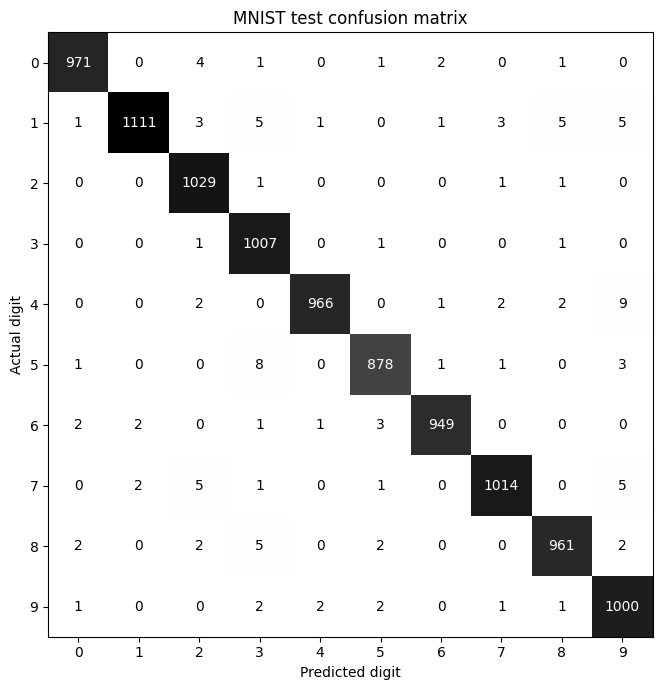

In [8]:
confusion_fig = make_confusion_figure(cm)
display(confusion_fig)
plt.close(confusion_fig)
print("Images in matrix:", int(cm.sum()))
print("Correct predictions on diagonal:", int(np.trace(cm)))


Rows contain actual digits and columns contain predictions. Diagonal cells are correct predictions; other cells are mistakes. The matrix shows which digits are confused, but it does not show why particular pixels caused a prediction.


## 9. Inspect the first 12 mistakes


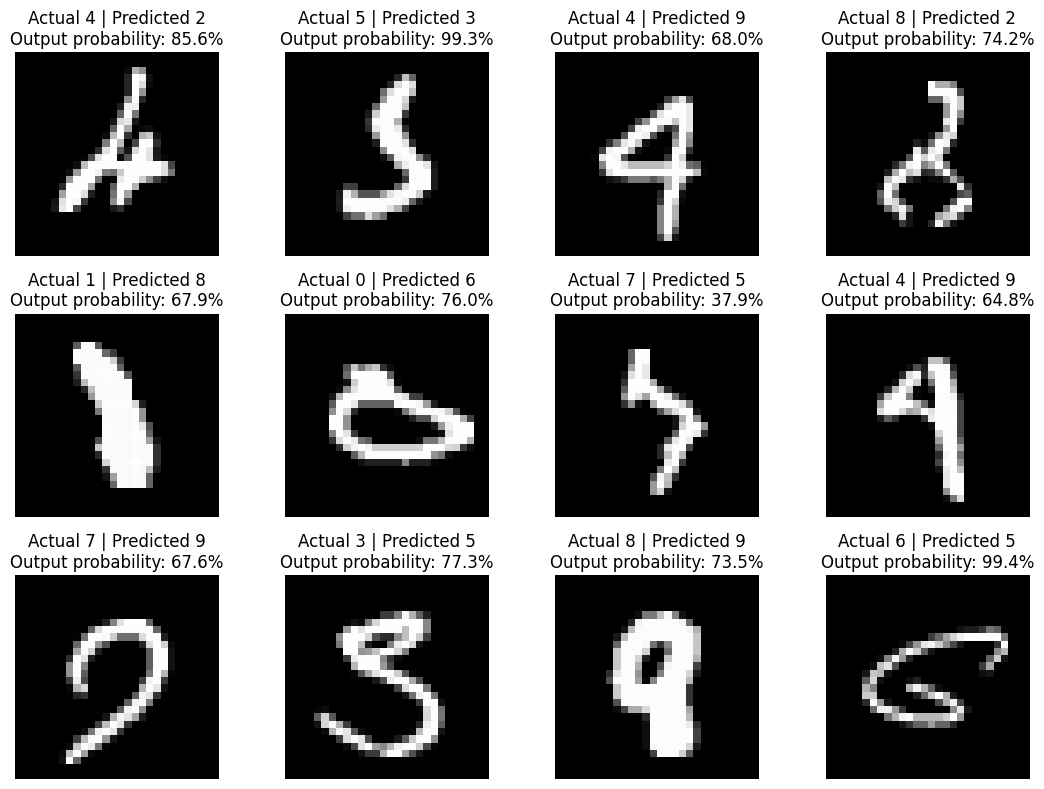

In [9]:
error_fig = make_error_figure(x_test, y_test, y_pred, probabilities, wrong_indices)
display(error_fig)
plt.close(error_fig)


The grid shows each actual digit, prediction and predicted-class output probability. These are the first 12 errors in test order, not a representative sample of all 114 mistakes. A high probability can still accompany a wrong prediction. Visual similarities suggest possible explanations but do not establish the model’s reasoning.


## 10. Rank repeated confusions


In [10]:
print(confusion_table.head(10).to_string(index=False))


 Actual digit  Predicted digit  Errors
            4                9       9
            5                3       8
            1                3       5
            1                8       5
            1                9       5
            7                2       5
            7                9       5
            8                3       5
            0                2       4
            1                2       3


We count each actual/predicted pair outside the diagonal and sort by error count. Ties are ordered by actual digit and then predicted digit. The largest pairs identify recurring weaknesses.


## 11. Check the supplied reference results


In [11]:
reference_checks = check_reference(summary, cm, REFERENCE_DIR)
summary.update(reference_checks)
print("Accuracy matches reference:", reference_checks["accuracy_matches_reference"])
print("Full confusion matrix matches reference:", reference_checks["confusion_matrix_matches_reference"])


Accuracy matches reference: True
Full confusion matrix matches reference: True


`np.isclose` allows a small numerical difference in accuracy. `np.array_equal` checks every confusion-matrix count. A mismatch stops the evaluation rather than silently saving a successful result. Matching these totals does not imply that all individual probabilities are identical.


## 12. Save the results


In [12]:
summary["checkpoint_sha256"] = checkpoint_sha256(MODEL_PATH)
summary["model_parameters"] = int(evaluation_model.count_params())
summary["tensorflow_version"] = tf.__version__
save_results(OUTPUT_DIR, report_data, cm, confusion_table, summary, confusion_fig, error_fig)
print(json.dumps(summary, indent=2))
print("Results saved:")
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(path.name)


{
  "test_images": 10000,
  "test_accuracy": 0.9886,
  "correct_predictions": 9886,
  "incorrect_predictions": 114,
  "macro_f1": 0.9886182412680771,
  "weighted_f1": 0.9886047786027109,
  "accuracy_matches_reference": true,
  "confusion_matrix_matches_reference": true,
  "checkpoint_sha256": "610103acd2a6ff353815c6861b0baca1e31060fd9e69503631ac00226579dbb2",
  "model_parameters": 421642,
  "tensorflow_version": "2.20.0"
}
Results saved:
classification_report.csv
confusion_matrix.csv
confusion_matrix.png
evaluation_summary.json
misclassified_examples.png
ranked_confusions.csv


CSV files store the numerical tables; JSON stores the summary and reference checks. PNG files store the two figures. The checkpoint hash identifies the exact trained model. Outputs are written to `results/section3/`, so the training references remain unchanged.


## Scope and contribution

Muhammadh Azwardeen completed preprocessing, restoration of the selected model for evaluation, performance metrics, the confusion matrix, error analysis, reference verification and result exports.

No retraining, model selection, explanation generation or adversarial testing is performed here. Reported scores apply to the official MNIST test set. Future model changes should use validation data, followed by a separate final test.

## References

- [Keras MNIST dataset](https://keras.io/api/datasets/mnist/)
- [scikit-learn classification report](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html)
- [scikit-learn confusion matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics/confusion_matrix.html)
